**Data Visualization using matplotlib
Problem Statement: Analyzing Air Quality Index (AQI) Trends in a City
Dataset: "City_Air_Quality.csv"
Description: The dataset contains information about air quality measurements in a specific
city over a period of time. It includes attributes such as date, time, pollutant levels (e.g., PM2.5,
PM10, CO), and the Air Quality Index (AQI) values. The goal is to use the matplotlib library
to create visualizations that effectively represent the AQI trends and patterns for different
pollutants in the city.
Tasks to Perform:
1. Import the "City_Air_Quality.csv" dataset.
2. Explore the dataset to understand its structure and content.
3. Identify the relevant variables for visualizing AQI trends, such as date, pollutant levels,
and AQI values.
4. Create line plots or time series plots to visualize the overall AQI trend over time.
5. Plot individual pollutant levels (e.g., PM2.5, PM10, CO) on separate line plots to
visualize their trends over time.
6. Use bar plots or stacked bar plots to compare the AQI values across different dates or
time periods.
7. Create box plots or violin plots to analyze the distribution of AQI values for different
pollutant categories.
8. Use scatter plots or bubble charts to explore the relationship between AQI values and
pollutant levels.
9. Customize the visualizations by adding labels, titles, legends, and appropriate color
schemes.**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('City_Air_Quality.csv')

df.head()

,Date,PM2.5,PM10,CO,AQI
0,2025-01-01,42.1,76.3,1.25,120
1,2025-01-02,46.3,82.3,1.25,121
2,2025-01-03,32.1,71.7,0.99,101
3,2025-01-04,37.9,58.5,1.02,111
4,2025-01-05,41.5,53.5,1.03,119


In [3]:
#Date	Measurement date
# PM2.5	Fine particulate matter
# PM10	Coarse particulate matter
# CO	Carbon monoxide
# AQI	Air Quality Index

In [4]:
print(df.shape)
print(df.info())
print(df.describe())
print(df.isnull().sum())

(150, 5)
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    150 non-null    str    
 1   PM2.5   150 non-null    float64
 2   PM10    150 non-null    float64
 3   CO      150 non-null    float64
 4   AQI     150 non-null    int64  
dtypes: float64(3), int64(1), str(1)
memory usage: 6.0 KB
None
            PM2.5        PM10          CO         AQI
count  150.000000  150.000000  150.000000  150.000000
mean    37.976667   65.491333    1.019067  104.006667
std     11.224927   21.524189    0.188100   26.366161
min     11.000000   12.000000    0.560000   29.000000
25%     29.350000   51.700000    0.890000   86.000000
50%     38.250000   63.950000    1.025000  103.000000
75%     45.700000   80.675000    1.167500  123.750000
max     64.300000  111.000000    1.490000  162.000000
Date     0
PM2.5    0
PM10     0
CO       0
AQI      0
dtype: int64


In [5]:
df['Date'] = pd.to_datetime(df['Date'])

df = df.drop_duplicates().sort_values('Date')

df[['PM2.5', 'PM10', 'CO', 'AQI']] = (
    df[['PM2.5', 'PM10', 'CO', 'AQI']]
    .apply(pd.to_numeric, errors='coerce')
)

df = df.dropna()

df.head()

,Date,PM2.5,PM10,CO,AQI
0,2025-01-01,42.1,76.3,1.25,120
1,2025-01-02,46.3,82.3,1.25,121
2,2025-01-03,32.1,71.7,0.99,101
3,2025-01-04,37.9,58.5,1.02,111
4,2025-01-05,41.5,53.5,1.03,119


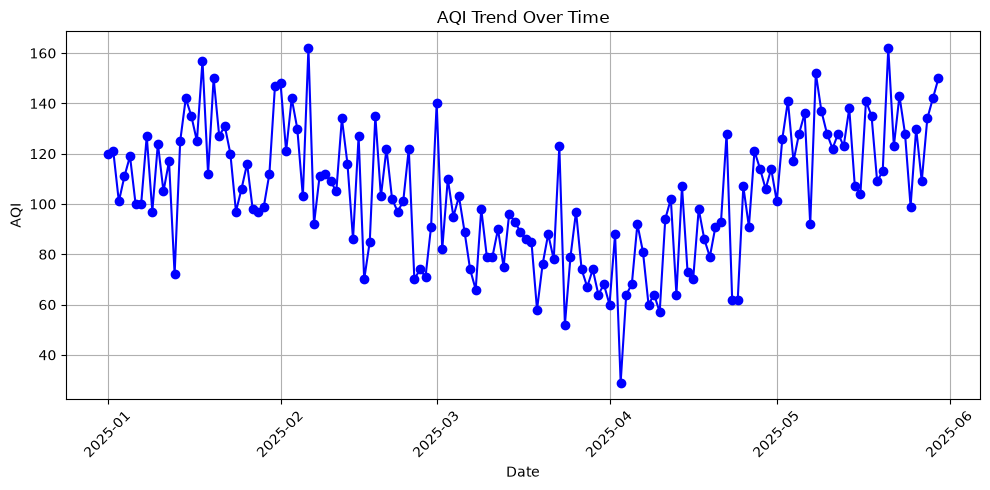

In [6]:
#overall AQL trend(Line plot)
plt.figure(figsize=(10, 5))

plt.plot(df['Date'], df['AQI'], color='blue', marker='o')

plt.title('AQI Trend Over Time')
plt.xlabel('Date')
plt.ylabel('AQI')
plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()

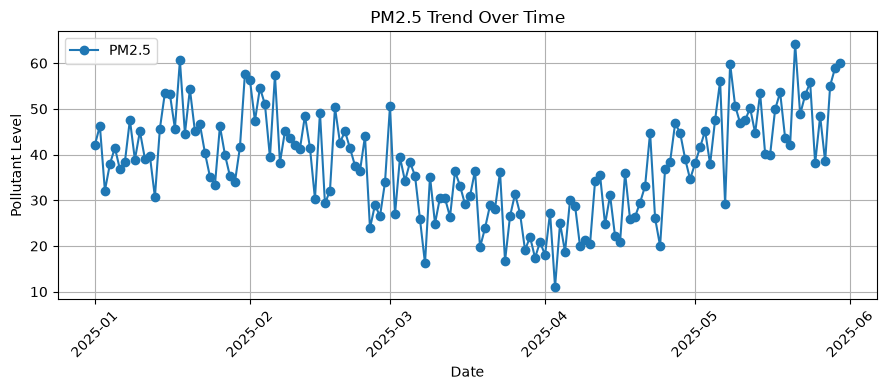

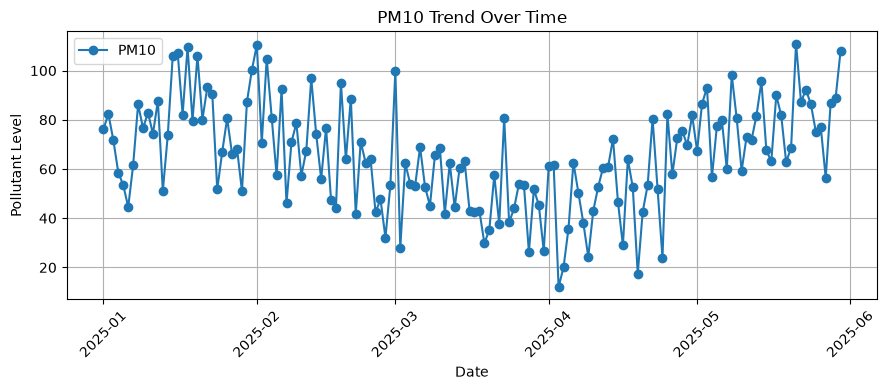

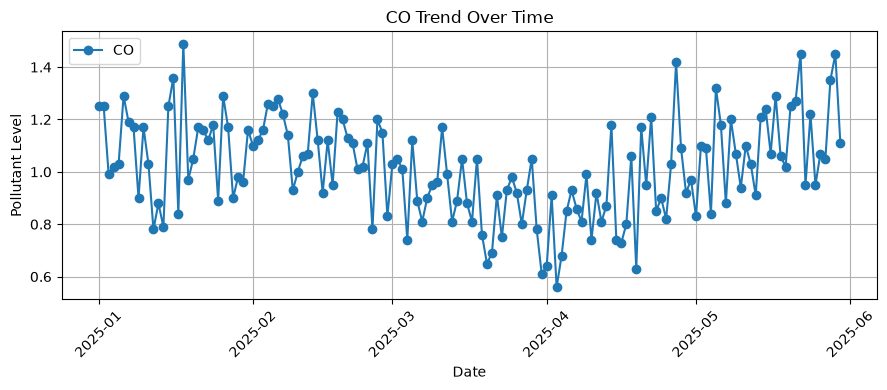

In [7]:
#individual pollutant trends
for col in ['PM2.5', 'PM10', 'CO']:
    plt.figure(figsize=(9, 4))
    plt.plot(df['Date'], df[col], marker='o', label=col)
    plt.title(col + ' Trend Over Time')
    plt.xlabel('Date')
    plt.ylabel('Pollutant Level')
    plt.legend()
    plt.grid()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

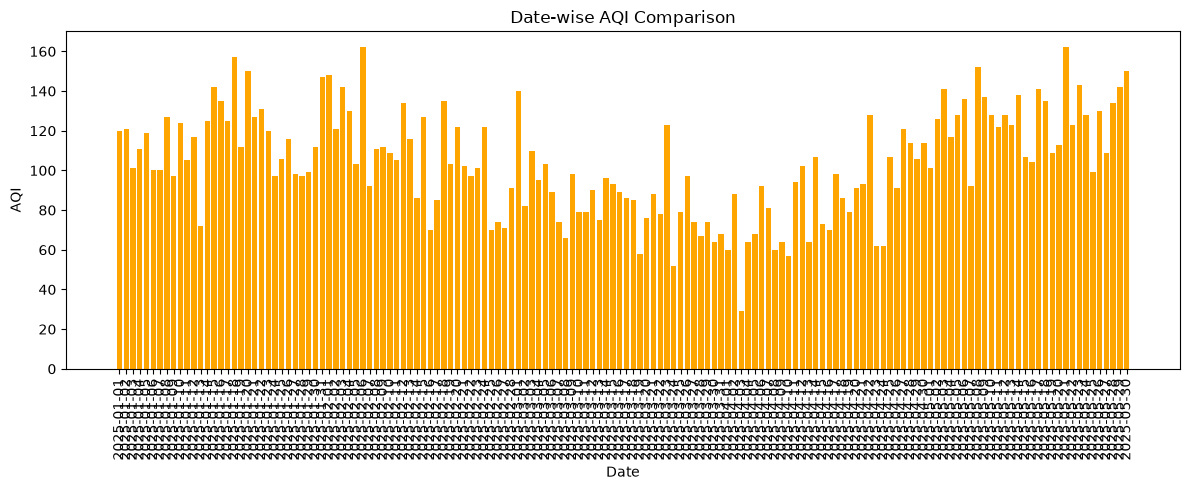

In [8]:
#Date Wise AQI(bar plot)
plt.figure(figsize=(12, 5))

plt.bar(df['Date'].astype(str), df['AQI'], color='orange')

plt.title('Date-wise AQI Comparison')
plt.xlabel('Date')
plt.ylabel('AQI')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

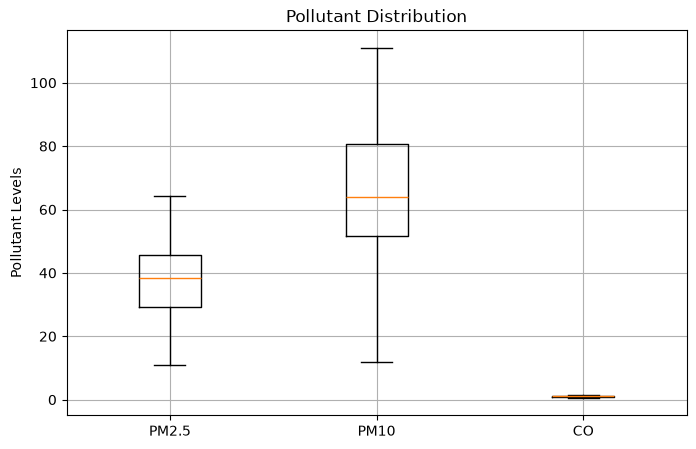

In [9]:
#pollutant Distribution(box plot)
plt.figure(figsize=(8, 5))

plt.boxplot(
    [df['PM2.5'], df['PM10'], df['CO']],
    tick_labels=['PM2.5', 'PM10', 'CO']
)

plt.title('Pollutant Distribution')
plt.ylabel('Pollutant Levels')
plt.grid()
plt.show()

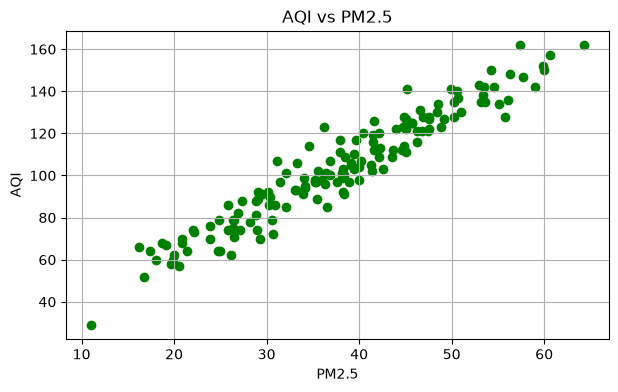

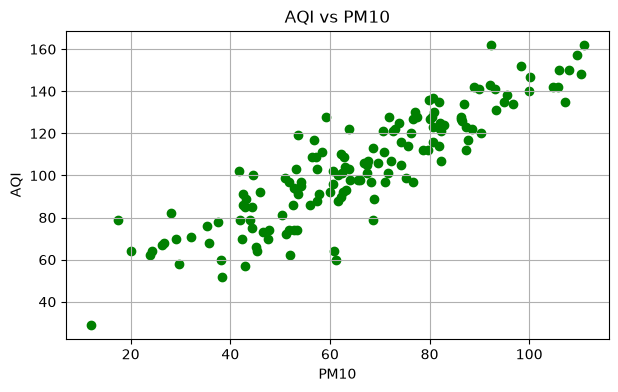

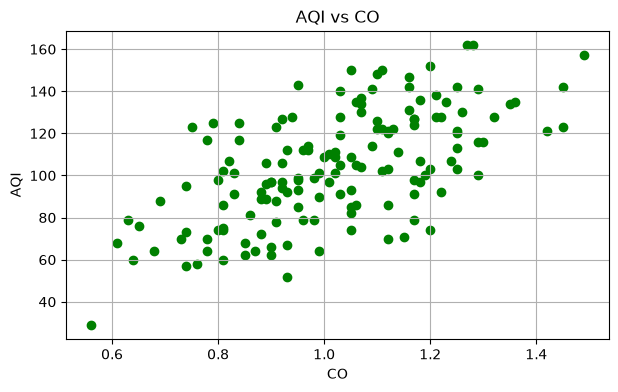

In [10]:
#AQI vs pollutants (Scatter Plot)
for col in ['PM2.5', 'PM10', 'CO']:
    plt.figure(figsize=(7, 4))
    plt.scatter(df[col], df['AQI'], color='green')
    plt.title('AQI vs ' + col)
    plt.xlabel(col)
    plt.ylabel('AQI')
    plt.grid()
    plt.show()

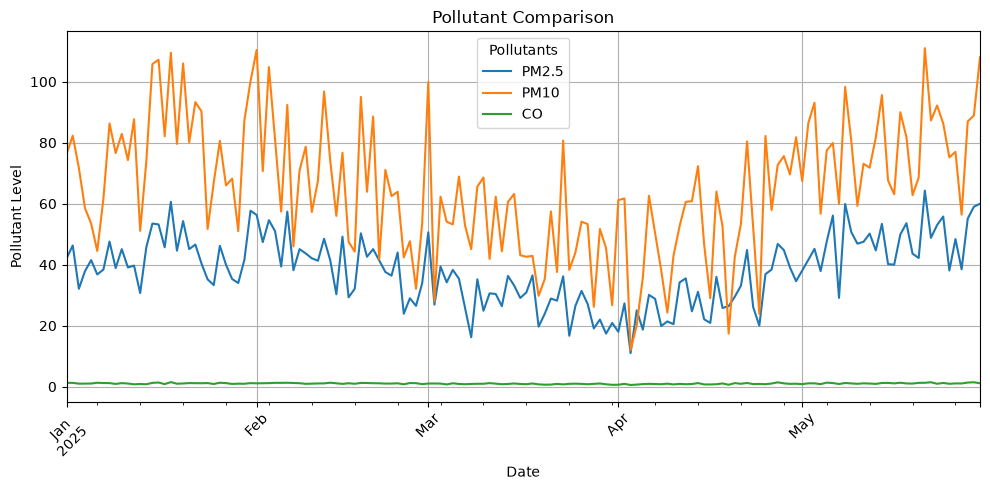

In [11]:
#combined pollutant comparison
df.plot(
    x='Date',
    y=['PM2.5', 'PM10', 'CO'],
    figsize=(10, 5),
    title='Pollutant Comparison',
    grid=True
)

plt.xlabel('Date')
plt.ylabel('Pollutant Level')
plt.legend(title='Pollutants')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [12]:
print("Average AQI:", df['AQI'].mean())
print("Maximum AQI:", df['AQI'].max())
print("Minimum AQI:", df['AQI'].min())

print("\nAverage Pollutant Levels:")
print(df[['PM2.5', 'PM10', 'CO']].mean())

Average AQI: 104.00666666666666
Maximum AQI: 162
Minimum AQI: 29

Average Pollutant Levels:
PM2.5    37.976667
PM10     65.491333
CO        1.019067
dtype: float64
